<a href="https://colab.research.google.com/github/futuregunmulju/2026-Signals-and-Systems-Speech-Noise-Reduction/blob/experiment%2Fminju/Challenge1_Experiment_Code_Set2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge
%pip install -q pesq==0.0.4 soundfile

Mounted at /content/drive
/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


# 10. 하모닉

In [2]:
import os, json, importlib
import numpy as np, pandas as pd, soundfile as sf
from IPython.display import display
from pesq import pesq
from tqdm.auto import tqdm
from multiprocessing import Pool

SR = 16_000
validation = pd.read_csv("validation/samples.csv")
train = pd.read_csv("train/samples.csv")

def read_pair(row):
    clean, _ = sf.read(row.clean_path, dtype="float64")
    noisy, _ = sf.read(row.noisy_path, dtype="float64")
    return clean, noisy

def snr_db(ref, x):
    return 10 * np.log10(np.sum(ref**2) / max(np.sum((ref - x)**2), 1e-12))

def safe_pesq(ref, deg):
    try:
        return pesq(SR, ref, deg, "wb")
    except Exception:
        return 1.04

def eval_val(params=None, verbose=True):
    params = params or {}
    recs = []
    for row in tqdm(validation.itertuples(index=False), total=len(validation), disable=not verbose):
        clean, noisy = read_pair(row)
        enh = np.clip(dn.denoise(noisy, SR, **params), -1, 1)
        recs.append({"noise_category": row.noise_category, "target_snr_db": row.target_snr_db,
                     "Noisy PESQ": safe_pesq(clean, noisy), "PESQ": safe_pesq(clean, enh),
                     "Noisy SNR": snr_db(clean, noisy), "SNR": snr_db(clean, enh)})
    return pd.DataFrame(recs)
print(f"Validation {len(validation)}쌍 | Train {len(train)}쌍")

Validation 164쌍 | Train 1296쌍


In [3]:
s = open("denoise.py").read()
assert "h_w" not in s, "denoise.py에 이미 하모닉 패치가 들어가 있어요. 알려주세요"

a = "from scipy.ndimage import gaussian_filter1d, minimum_filter1d, uniform_filter, uniform_filter1d"
b = "from scipy.ndimage import gaussian_filter1d, median_filter, minimum_filter1d, uniform_filter, uniform_filter1d"
assert a in s; s = s.replace(a, b, 1)

a = "def _lsa(xi, gamma):"
b = '''def _harmonic_mult(P, fr, sr, n_fft, h_lo, h_pow, z0, fmax):
    """Pitch-based harmonic comb (cepstral F0 per frame). m(K,T) in [h_lo,1], voicing confidence v(T)."""
    c = np.fft.irfft(np.log(P), n=n_fft, axis=0)
    qa, qb = int(sr / 400), int(sr / 80)
    qb = min(qb, n_fft // 2 - 3)
    seg = c[qa:qb + 1]
    seg = seg - uniform_filter1d(seg, 15, axis=0, mode="nearest")
    Q, T = seg.shape
    idx = np.arange(T)
    i = np.argmax(seg, axis=0)
    peak = seg[i, idx]
    z = (peak - seg.mean(axis=0)) / (seg.std(axis=0) + 1e-9)
    y0, y2 = seg[np.clip(i - 1, 0, Q - 1), idx], seg[np.clip(i + 1, 0, Q - 1), idx]
    den = y0 - 2 * peak + y2
    delta = np.clip(np.where(np.abs(den) > 1e-12, 0.5 * (y0 - y2) / den, 0.0), -1, 1)
    q = median_filter(qa + i + delta, size=5, mode="nearest")
    f0 = sr / q
    v = uniform_filter1d(np.clip((z - z0) / 2.0, 0.0, 1.0), 3, mode="nearest")
    comb = (0.5 * (1 + np.cos(2 * np.pi * fr[:, None] / f0[None, :]))) ** h_pow
    m = h_lo + (1 - h_lo) * comb
    m = np.where(fr[:, None] <= fmax, m, 1.0)
    return m, v


def _lsa(xi, gamma):'''
assert a in s; s = s.replace(a, b, 1)

a = "    pause_thr=2.0,\n)"
b = ("    pause_thr=2.0,\n    h_w=0.0,\n    h_lo=0.4,\n    h_pow=3.0,\n    h_z0=2.5,\n    h_fmax=2500.0,\n)")
assert a in s; s = s.replace(a, b, 1)

a = '    fp_db = p["floor_pause_db"]\n    if fp_db is None:\n        floor_t = np.full(T, floor)'
b = ('    HM = None\n'
     '    if p["h_w"] > 0:\n'
     '        m_, v_ = _harmonic_mult(P, fr, sr, n_fft, p["h_lo"], p["h_pow"], p["h_z0"], p["h_fmax"])\n'
     '        HM = 1.0 - p["h_w"] * v_[None, :] * (1.0 - m_)\n'
     '    fp_db = p["floor_pause_db"]\n    if fp_db is None:\n        floor_t = np.full(T, floor)')
assert a in s; s = s.replace(a, b, 1)

a = '        g = np.clip(_lsa(xi, gamma), floor_t[t], 1.0)'
b = ('        if HM is not None:\n'
     '            xi = np.maximum(xi * HM[:, t], xi_min)\n'
     '        g = np.clip(_lsa(xi, gamma), floor_t[t], 1.0)')
assert a in s; s = s.replace(a, b, 1)

s = s.replace('"best_params.json"', '"best_params_harm.json"')     # 이 노트북 전용 설정 파일
open("denoise_harm.py", "w").write(s)

import shutil
shutil.copy("best_params.json", "best_params_harm.json")            # 지금 시점의 최고 설정을 복사해서 시작
import denoise_harm as dn
importlib.reload(dn)
print("준비 완료 | h_w 기본값", dn.DEFAULTS["h_w"], "| hp_hz", dn.DEFAULTS["hp_hz"], "| floor_pause_db", dn.DEFAULTS["floor_pause_db"])

준비 완료 | h_w 기본값 0.0 | hp_hz 100.0 | floor_pause_db -26


In [4]:
cas = eval_val()
cas["PESQ Gain"] = cas["PESQ"] - cas["Noisy PESQ"]
print(f"시작 Validation WB-PESQ: {cas['PESQ'].mean():.4f}")

  0%|          | 0/164 [00:00<?, ?it/s]

시작 Validation WB-PESQ: 1.8255


In [5]:
sub = train.sample(80, random_state=2).reset_index(drop=True)
PAIRS = [read_pair(r) for r in sub.itertuples()]

def _score(a):
    i, params = a
    clean, noisy = PAIRS[i]
    return safe_pesq(clean, np.clip(dn.denoise(noisy, SR, **params), -1, 1))

def eval_train(params, pool):
    return float(np.mean(pool.map(_score, [(i, params) for i in range(len(PAIRS))])))

SPACE = dict(h_w=(0.3, 1.0), h_lo=(0.1, 0.6), h_pow=[2.0, 3.0, 4.0, 6.0],
             h_z0=(1.0, 3.5), h_fmax=[1500.0, 2000.0, 2500.0, 3500.0],
             floor_pause_db=(-45, -22), gain_floor_db=(-24, -14))

def perturb(p, rng):
    q = dict(p)
    for k in rng.choice(list(SPACE), size=2, replace=False):
        v = SPACE[k]
        if isinstance(v, list):
            q[k] = v[rng.integers(len(v))]
        else:
            lo, hi = v
            cur_v = p.get(k) if p.get(k) is not None else (lo + hi) / 2
            q[k] = float(np.clip(cur_v + rng.normal(0, 0.2 * (hi - lo)), lo, hi))
    return q

rng = np.random.default_rng(11)
N_ITER = 20
with Pool(os.cpu_count()) as pool:          # PAIRS, dn 정의 뒤에 Pool을 만들 것
    cur = dict(dn.DEFAULTS); cur_s = eval_train(cur, pool)
    print(f"하모닉 끔(기준) {cur_s:.4f}")
    start = {**cur, "h_w": 0.8, "h_lo": 0.3, "h_z0": 1.8}
    s0 = eval_train(start, pool)
    print(f"하모닉 켬(시작) {s0:.4f}")
    if s0 > cur_s:
        cur, cur_s = start, s0
    for t in range(N_ITER):
        cand = perturb(cur, rng)
        s = eval_train(cand, pool)
        if s > cur_s:
            cur, cur_s = cand, s
        print(f"iter {t+1:2d}: 시도 {s:.4f} | 현재 최고 {cur_s:.4f}", flush=True)

new = eval_val(cur)
print(f"Validation: {cas['PESQ'].mean():.4f} → {new['PESQ'].mean():.4f}")
display(pd.DataFrame({"이전": cas.groupby("target_snr_db")["PESQ"].mean(),
                      "새 설정": new.groupby("target_snr_db")["PESQ"].mean()}).round(3))
if new["PESQ"].mean() > cas["PESQ"].mean() + 0.005:
    json.dump(cur, open("best_params_harm.json", "w"), indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else o)
    cas = new
    print("채택 → best_params_harm.json 갱신")
else:
    print("개선 미미 → 기존 유지")
print({k: cur[k] for k in ("h_w", "h_lo", "h_pow", "h_z0", "h_fmax", "floor_pause_db")})

하모닉 끔(기준) 1.7906
하모닉 켬(시작) 1.7854
iter  1: 시도 1.7918 | 현재 최고 1.7918
iter  2: 시도 1.7921 | 현재 최고 1.7921
iter  3: 시도 1.7917 | 현재 최고 1.7921
iter  4: 시도 1.7902 | 현재 최고 1.7921
iter  5: 시도 1.7911 | 현재 최고 1.7921
iter  6: 시도 1.7917 | 현재 최고 1.7921
iter  7: 시도 1.7922 | 현재 최고 1.7922
iter  8: 시도 1.7926 | 현재 최고 1.7926
iter  9: 시도 1.7919 | 현재 최고 1.7926
iter 10: 시도 1.7916 | 현재 최고 1.7926
iter 11: 시도 1.7927 | 현재 최고 1.7927
iter 12: 시도 1.7925 | 현재 최고 1.7927
iter 13: 시도 1.7921 | 현재 최고 1.7927
iter 14: 시도 1.7921 | 현재 최고 1.7927
iter 15: 시도 1.7924 | 현재 최고 1.7927
iter 16: 시도 1.7926 | 현재 최고 1.7927
iter 17: 시도 1.7923 | 현재 최고 1.7927
iter 18: 시도 1.7926 | 현재 최고 1.7927
iter 19: 시도 1.7918 | 현재 최고 1.7927
iter 20: 시도 1.7922 | 현재 최고 1.7927


  0%|          | 0/164 [00:00<?, ?it/s]

Validation: 1.8255 → 1.8323


,이전,새 설정
target_snr_db,,
0.0,1.239,1.243
5.0,1.569,1.575
10.0,1.839,1.846
15.0,2.144,2.151


채택 → best_params_harm.json 갱신
{'h_w': 0.376253493108925, 'h_lo': 0.3532402441107253, 'h_pow': 2.0, 'h_z0': 2.2363079034832873, 'h_fmax': 2500.0, 'floor_pause_db': -29.084602788964247}


## 10-2. Machine 스펙트로그램

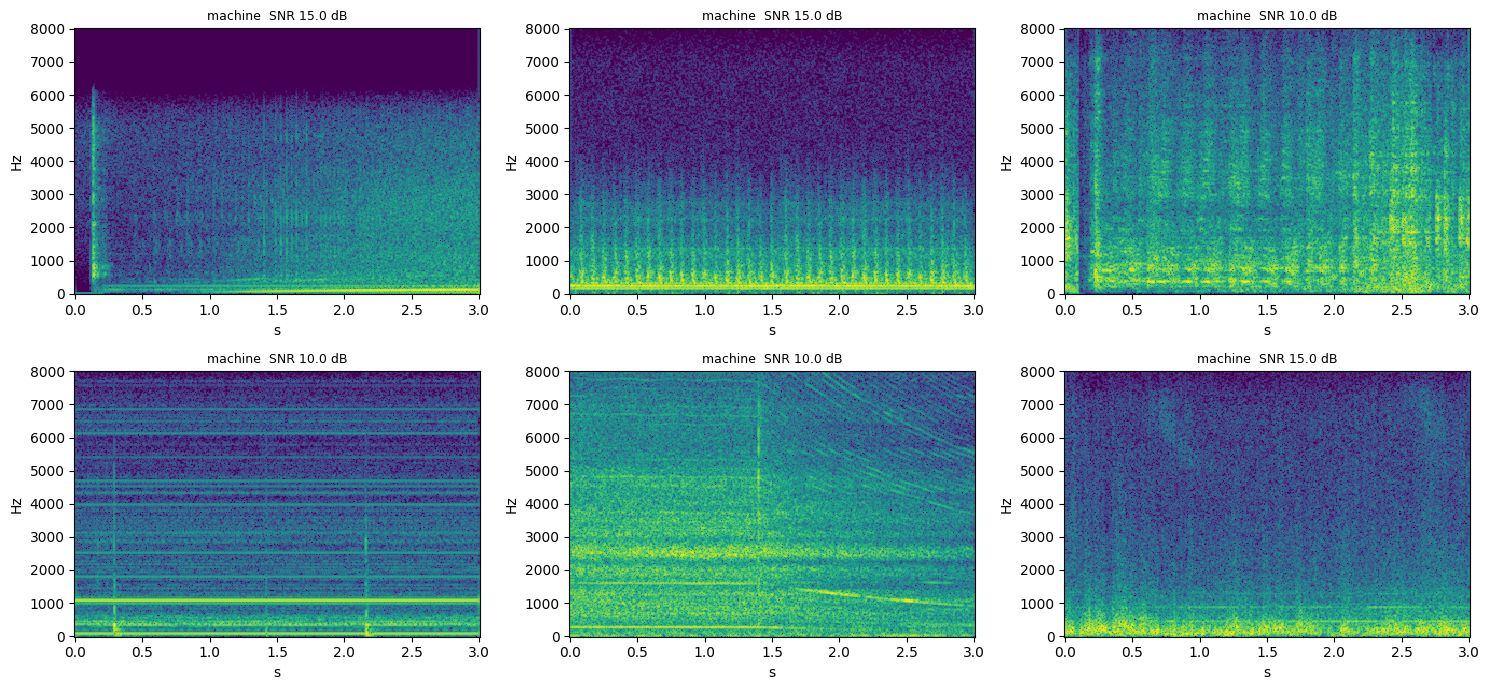

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47141 (\N{HANGUL SYLLABLE RYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw

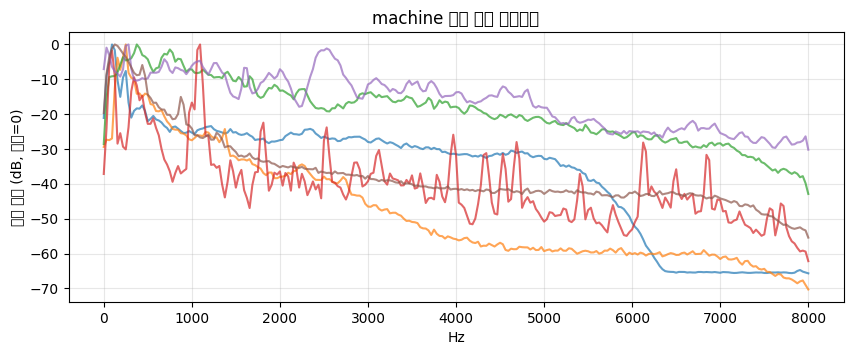

In [6]:
import numpy as np, matplotlib.pyplot as plt
from scipy.signal import stft

reader = globals().get("read_validation_pair") or globals().get("read_pair")
assert reader is not None, "읽기 함수(read_validation_pair / read_pair)가 없어요. 이름을 알려주세요."

rows = validation[validation["noise_category"].eq("machine")].head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
spectra = []
for ax, row in zip(axes.ravel(), rows.itertuples(index=False)):
    clean, noisy = reader(row)
    n = min(len(clean), len(noisy))
    noise = np.asarray(noisy[:n], float) - np.asarray(clean[:n], float)
    f, t, Z = stft(noise, fs=16000, nperseg=512, noverlap=384)
    S = 10 * np.log10(np.abs(Z) ** 2 + 1e-12)
    ax.pcolormesh(t, f, S, shading="auto", vmin=S.max() - 70, vmax=S.max())
    ax.set_title(f"machine  SNR {getattr(row, 'target_snr_db', '?')} dB", fontsize=9)
    ax.set_ylabel("Hz"); ax.set_xlabel("s")
    spectra.append(S.mean(axis=1))
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3.5))
for s in spectra:
    plt.plot(f, s - s.max(), alpha=0.7)
plt.xlabel("Hz"); plt.ylabel("평균 전력 (dB, 최대=0)"); plt.title("machine 잡음 평균 스펙트럼")
plt.grid(alpha=0.3); plt.show()

In [7]:
importlib.reload(dn) if "dn" in globals() else None
print({k: v for k, v in dn.DEFAULTS.items() if "ton" in k or "notch" in k})

{'tonal_db': 18.0, 'tonal_max_cut_db': 20.0, 'tonal_max_peaks': 5}


In [8]:
import json, re

for fn in ["denoise.py", "denoise_harm.py"]:
    try:
        s = open(fn).read()
    except FileNotFoundError:
        print(fn, "없음"); continue
    hits = [l.strip() for l in s.splitlines() if re.search(r"ton|notch", l) and "=" in l]
    print(f"\n[{fn}] 톤/노치 관련 줄:")
    for h in hits[:15]:
        print("  ", h)

for fn in ["best_params.json", "best_params_harm.json"]:
    try:
        p = json.load(open(fn))
        print(f"\n[{fn}]", {k: v for k, v in p.items() if "ton" in k or "notch" in k})
    except FileNotFoundError:
        print(fn, "없음")


[denoise.py] 톤/노치 관련 줄:
   tonal_db=0.0,          # 0 = off
   tonal_max_cut_db=20.0,
   tonal_max_peaks=5,
   xh = _tonal_suppress(xh, sr, p["tonal_db"], p["tonal_max_cut_db"], int(p["tonal_max_peaks"]))

[denoise_harm.py] 톤/노치 관련 줄:
   tonal_db=0.0,          # 0 = off
   tonal_max_cut_db=20.0,
   tonal_max_peaks=5,
   xh = _tonal_suppress(xh, sr, p["tonal_db"], p["tonal_max_cut_db"], int(p["tonal_max_peaks"]))

[best_params.json] {'tonal_db': 18.0, 'tonal_max_cut_db': 20.0, 'tonal_max_peaks': 5}

[best_params_harm.json] {'tonal_db': 18.0, 'tonal_max_cut_db': 20.0, 'tonal_max_peaks': 5}
